# Лекция 11. Прямые методы решения плотных СЛУ и декомпозиция матриц

Почти любая расчётная задача в итоге упирается в решение системы линейных
алгебраических уравнений (СЛАУ) $Ax = b$: модели либо сразу линейны, либо
приводятся к линейным **дискретизацией** (замена дифференциальных уравнений
разностными/сеточными) и **линеаризацией**. Поэтому трудно переоценить роль,
которую играет выбор эффективного способа решения СЛАУ. В этой лекции —
**прямые методы**: они приводят к решению за конечное число арифметических
операций (потому и называются «точными»; в идеальной арифметике — к точному
решению), а попутно выдают определители, обратные матрицы и **декомпозиции**
(факторизации) матриц: $A = LU$, $A = U^\top U$, $A = U^\top \mathcal{D} U$,
$A = U\Sigma V^\top$.

План лекции:

1. постановка задачи; почему формулы Крамера непригодны;
2. нормы векторов и матриц;
3. обусловленность СЛАУ: множитель ошибок $\mathrm{cond}(A)$; невязка
   и итерационное уточнение;
4. метод Гаусса с выбором главного элемента и LU-разложение
   (теорема 2.1, компактная схема, обращение по формулам (2.15)–(2.17));
5. метод квадратных корней (схема Холецкого) для симметричных систем
   и LU-подобное разложение $U^\top \mathcal{D} U$;
6. метод вращений (ортогональные преобразования) и сингулярное
   разложение (SVD);
7. трёхдиагональные матрицы: метод прогонки (теорема 2.2);
8. итоги: арифметическая сложность прямых методов.

> ❓ **Вопрос лекции.** Формулы Крамера $x_i = \det A_i / \det A$ дают
> «бесплатную» формулу решения, но вычисление $n+1$ определителя «в лоб»
> стоит порядка $n!$ умножений: при $n = 20$ это уже $\sim 5\cdot 10^{19}$
> операций (тысячи лет работы машины), при $n = 100$ — $\sim 10^{160}$,
> что больше числа атомов во Вселенной. Метод Гаусса решает ту же задачу
> за $\approx n^3/3$ умножений и делений ($20^3/3 \approx 2700$ —
> микросекунды), а трёхдиагональную систему — за $\sim 5n$ операций.
> Откуда берётся такая разница, и что нужно проверить, прежде чем
> поверить выданному прямым методом ответу?


In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(linewidth=120, precision=4, suppress=True)

print('Библиотеки загружены. numpy', np.__version__)
print('Печать массивов: 120 колонок, до 4 значащих цифр')


Библиотеки загружены. numpy 1.26.4
Печать массивов: 120 колонок, до 4 значащих цифр


## 1. 🎯 Постановка задачи и проклятие формул Крамера

Решаем **систему $n$ линейных алгебраических уравнений** (СЛАУ)

$$a_{i1}x_1 + a_{i2}x_2 + \dots + a_{in}x_n = b_i, \qquad i = 1,\dots,n
\quad\Longleftrightarrow\quad Ax = b.$$

Все методы её решения делятся на два класса:

- **прямые** — приводят к решению за конечное число арифметических
  операций (следствие: в идеальной арифметике ответ *точный*);
- **итерационные** — строят сходящуюся последовательность приближений
  (это уже следующий раздел курса).

По формулам Крамера $x_i = \det A_i / \det A$ решение выражается явно,
но вычислительно это провал: нужно $n+1$ определителей, а вычисление
каждого определителя разложениями по строке требует порядка $n!$
умножений. Итого $\sim (n+1)\cdot n!$: при $n = 20$ — порядка
$5\cdot 10^{19}$ операций, при $n = 30$ — уже $\sim 10^{33}$, при
$n = 100$ — $\sim 10^{160}$. Прямой ход метода Гаусса обрабатывает ту же
матрицу за $\approx n^3/3$ умножений и делений — при $n = 20$ это всего
$\sim 2700$ операций.

**Сквозной пример этой лекции (пример 2.1 учебника)** — матрица

$$A = \begin{pmatrix} 2 & -1 & 1 \\ 4 & 3 & 1 \\ 6 & -13 & 6 \end{pmatrix},
\qquad \det A = 2 \cdot 5 \cdot 1 = 10,$$

на которой мы пройдём и метод Гаусса, и LU-разложение
($L = \begin{pmatrix}1&0&0\\2&1&0\\3&-2&1\end{pmatrix}$,
$U = \begin{pmatrix}2&-1&1\\0&5&-1\\0&0&1\end{pmatrix}$), и обращение.


## 2. 📏 Нормы векторов и матриц: чем измеряем погрешности

Норма — способ измерять «величину» вектора: функция $\|x\|$ со свойствами
(1) $\|x\| \ge 0$ и $\|x\| = 0 \Leftrightarrow x = 0$;
(2) $\|\alpha x\| = |\alpha|\,\|x\|$;
(3) $\|x+y\| \le \|x\| + \|y\|$.

Базовые векторные нормы:

$$\|x\|_1 = \sum_{i=1}^n |x_i|, \qquad
\|x\|_2 = \Big(\sum_{i=1}^n x_i^2\Big)^{1/2}, \qquad
\|x\|_\infty = \max_{1\le i\le n}|x_i|,$$

и они согласованы между собой (важнейшие две цепочки):

$\ \|x\|_\infty \le \|x\|_2 \le \sqrt{n}\,\|x\|_\infty,
\qquad \|x\|_2 \le \|x\|_1 \le \sqrt{n}\,\|x\|_2.$

**Матричные нормы** — операторные (согласованные): $\|A\| = \max_{x\ne 0}
\|Ax\|/\|x\|$, так что $\|Ax\| \le \|A\|\,\|x\|$ выполняется автоматически:

$$\|A\|_1 = \max_{1\le j\le n}\sum_{i=1}^n |a_{ij}|
   \ \text{ (максимальная сумма по столбцам)},$$
$$\|A\|_\infty = \max_{1\le i\le n}\sum_{j=1}^n |a_{ij}|
   \ \text{ (максимальная сумма по строкам)},$$
$$\|A\|_2 = \sqrt{\lambda_{\max}(A^\top A)} = \sigma_{\max}(A)
   \ \text{ (максимальное сингулярное число)}.$$

Через нормы записываются все оценки точности этой лекции, включая
множитель ошибок $\mathrm{cond}(A) = \|A\|\|A^{-1}\|$ (§3).


In [ ]:
# вычислительно: нормы на сквозной матрице примера 2.1
A1 = np.array([[2., -1., 1.], [4., 3., 1.], [6., -13., 6.]])
A1inv = np.linalg.inv(A1)
x = np.array([1., 2., 3.])
Ax = A1 @ x

print('нормы вектора x = (1, 2, 3):')
print('  |x|1 =', np.linalg.norm(x, 1),
      ' |x|2 =', round(np.linalg.norm(x, 2), 6),
      ' |x|inf =', np.linalg.norm(x, np.inf))

print('нормы матрицы A (пример 2.1):')
print('  |A|1 =', np.linalg.norm(A1, 1),
      ' (макс. сумма по столбцам; суммы: 12, 17, 8)')
print('  |A|2 =', round(np.linalg.norm(A1, 2), 6),
      ' (= sigma_max =',
      round(np.linalg.svd(A1, compute_uv=False)[0], 6), ')')
print('  |A|inf =', np.linalg.norm(A1, np.inf),
      ' (макс. сумма по строкам; суммы: 4, 8, 25)')

print('согласованность: Ax =', Ax.tolist(),
      ' |Ax|inf =', np.linalg.norm(Ax, np.inf),
      '<= |A|inf * |x|inf =',
      np.linalg.norm(A1, np.inf) * np.linalg.norm(x, np.inf))

print('нормы обратной матрицы (понадобятся в cond):')
print('  |A^-1|1 =', np.linalg.norm(A1inv, 1),
      ' |A^-1|2 =', round(np.linalg.norm(A1inv, 2), 6),
      ' |A^-1|inf =', np.linalg.norm(A1inv, np.inf))


нормы вектора x = (1, 2, 3):
  |x|1 = 6.0  |x|2 = 3.741657  |x|inf = 3.0
нормы матрицы A (пример 2.1):
  |A|1 = 17.0  (макс. сумма по столбцам; суммы: 12, 17, 8)
  |A|2 = 15.662821  (= sigma_max = 15.662821 )
  |A|inf = 25.0  (макс. сумма по строкам; суммы: 4, 8, 25)
согласованность: Ax = [3.0, 13.0, -2.0]  |Ax|inf = 13.0 <= |A|inf * |x|inf = 75.0
нормы обратной матрицы (понадобятся в cond):
  |A^-1|1 = 11.900000000000006  |A^-1|2 = 8.237704  |A^-1|inf = 10.000000000000004


## 3. 🌡️ Обусловленность СЛАУ: множитель ошибок $\mathrm{cond}(A)$

Пусть данными при решении $Ax = b$ стал «испорченный» вектор
$b + \Delta b$ (например, из-за машинного округления). Решение тогда
$x + \Delta x$, где $\Delta x = A^{-1}\Delta b$ — матрица задачи не
меняется! Для относительных погрешностей отсюда стандартная оценка
(теорема об обусловленности):

$$\frac{\|\Delta x\|}{\|x\|} \;\le\;
\underbrace{\|A\|\;\|A^{-1}\|}_{=\ \mathrm{cond}(A)}\;
\frac{\|\Delta b\|}{\|b\|},
\qquad \mathrm{cond}(A) = \|A\|\|A^{-1}\| \ge 1.$$

Свойства и смысл:

- $\mathrm{cond}(A) \ge 1$ всегда; «хорошие» системы: cond порядка
  единиц–десятков; тогда малые относительные ошибки данных дают малые
  относительные ошибки ответа.
- $\mathrm{cond}_2(A) = \sigma_1/\sigma_n$ — отношение крайних
  сингулярных чисел (см. §6); $\mathrm{cond}_1, \mathrm{cond}_\infty$
  — с соответствующими нормами.
- **Плохо обусловленная** (ill-conditioned) система: cond огромен —
  малые ошибки в данных усиливаются в тысячи–миллионы раз. Если
  $\mathrm{cond}(A) \gtrsim 1/\varepsilon_{\text{mach}}$ (при double
  $\varepsilon \approx 10^{-16}$), то даже точный метод не гарантирует
  ни одной верной цифры ответа.

**Невязка — не ошибка.** Невязка $r = b - Ax^\wedge$ показывает, какому
*возмущённому* $b$ найденный $x^\wedge$ отвечает точно; при большом
cond малая невязка не мешает巨大 ошибке $\|x^\wedge - x\|$.

**Итерационное уточнение (§ 2.8.1 учебника).** Дешёвый способ подстегнуть
точность прямых методов: решив $Ax^{(0)} = b$ (прямой ход уже сделан и
хранится в LU), считаем невязку $r^{(0)} = b - Ax^{(0)}$, находим
поправку $p$ из $Ap = r^{(0)}$ (только обратные подстановки) и положим
$x^{(1)} = x^{(0)} + p$; повторяем 1–3 раза. Если невязки не
сходятся — система плохо обусловлена и без дополнительных данных о
задаче её нельзя решить требуемым образом.


упр. 2.1: плохо обусловленная система (det почти нулевой)
  det A21 = 0.020001000000000886
  cond1 = 617878.53  cond2 = 405954.15  condinf = 582819.05
  решение (полная точность): x = [3.   0.2  0.01]  |невязка| = 0.0
  теорема: сдвиг b[j] на +0.01; множитель cond2*|db|2/|b|2 = 1158.937
    j=0: |dx|/|x| = 43.556   (граница теоремы ~1159)
    j=1: |dx|/|x| = 16.750   (граница теоремы ~1159)
    j=2: |dx|/|x| = 1.682   (граница теоремы ~1159)
матрица Гильберта 3x3: cond1 = 748.0  cond2 = 524.057  condinf = 748.0
  сингулярные числа: [1.408318927, 0.122327066, 0.00268734]  cond2 = sigma1/sigma3 = 524.057
  H3^-1 (огромные элементы = признак плохой обусловленности):
[[   9.  -36.   30.]
 [ -36.  192. -180.]
 [  30. -180.  180.]]
  cond(H5) = 476607.3
упр. 2.1В: Гаусс в 3-значной арифметике и упр. 2.1Г: уточнение
  pivot=False: x = [12.1, -0.25, 0.0105] |относит.ошибка 3.0333, невязка 1.800e-02|
    после уточнения: x = [3.0, 0.2, 0.01] |невязка 8.882e-16|
  pivot=True: x = [3.65, 0.167, 0

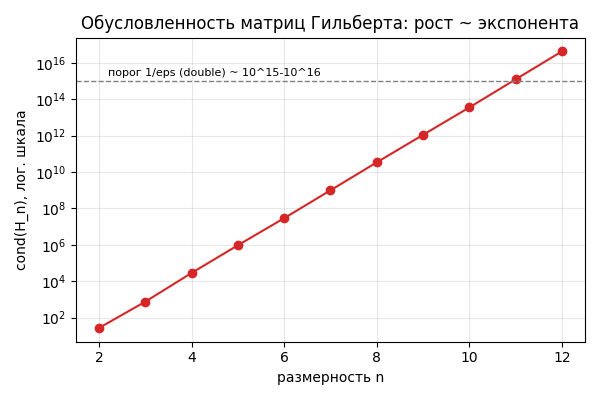

In [ ]:
# ---------------------------------------------------------- упр. 2.1: ill-conditioned система
A21 = np.array([[0.1, 2., -10.], [0.3, 6.01, -25.], [0.4, 8.06, 10.001]])
b21 = np.array([0.6, 1.852, 2.91201])
x21 = np.linalg.solve(A21, b21)

print('упр. 2.1: плохо обусловленная система (det почти нулевой)')
print('  det A21 =', np.linalg.det(A21))
print('  cond1 =', round(np.linalg.cond(A21, 1), 2),
      ' cond2 =', round(np.linalg.cond(A21, 2), 2),
      ' condinf =', round(np.linalg.cond(A21, np.inf), 2))
print('  решение (полная точность): x =', x21,
      ' |невязка| =', np.max(np.abs(b21 - A21 @ x21)))

bound = np.linalg.cond(A21, 2) * 0.01 / np.linalg.norm(b21, 2)
print('  теорема: сдвиг b[j] на +0.01; множитель cond2*|db|2/|b|2 =',
      round(bound, 3))
for j in range(3):
    db = np.zeros(3)
    db[j] = 0.01
    rel = np.linalg.norm(np.linalg.solve(A21, db), 2) / np.linalg.norm(x21, 2)
    print(f'    j={j}: |dx|/|x| = {rel:.3f}   (граница теоремы ~{bound:.0f})')

# ---------------------------------------------------------- матрица Гильберта
H3 = np.array([[1 / (i + j + 1) for j in range(3)] for i in range(3)])
sig = np.linalg.svd(H3, compute_uv=False)
print('матрица Гильберта 3x3: cond1 =', round(np.linalg.cond(H3, 1), 3),
      ' cond2 =', round(np.linalg.cond(H3, 2), 3),
      ' condinf =', round(np.linalg.cond(H3, np.inf), 3))
print('  сингулярные числа:', np.round(sig, 9).tolist(),
      ' cond2 = sigma1/sigma3 =', round(sig[0] / sig[-1], 3))
print('  H3^-1 (огромные элементы = признак плохой обусловленности):')
print(np.linalg.inv(H3))
print('  cond(H5) =', round(np.linalg.cond(
    np.array([[1 / (i + j + 1) for j in range(5)] for i in range(5)]), 2), 1))

# ---------------------------------------------------------- 3-значный Гаусс (упр. 2.1В) и уточнение (упр. 2.1Г)
def fl3(v):
    return float(f'{v:.3g}')

def gauss3(A, b, pivot):
    A = [[fl3(v) for v in row] for row in A]
    b = [fl3(v) for v in b]
    n = len(A)
    for k in range(n - 1):
        if pivot:
            p = max(range(k, n), key=lambda i: abs(A[i][k]))
            A[k], A[p] = A[p], A[k]
            b[k], b[p] = b[p], b[k]
        if abs(A[k][k]) < 1e-12:
            return None, 'останавливаемся: ведущий элемент ~ 0'
        for i in range(k + 1, n):
            l = fl3(A[i][k] / A[k][k])
            A[i][k] = 0.0
            for j in range(k + 1, n):
                A[i][j] = fl3(A[i][j] - fl3(l * A[k][j]))
            b[i] = fl3(b[i] - fl3(l * b[k]))
    x = [0.0] * n
    for k in range(n - 1, -1, -1):
        s = b[k]
        for j in range(k + 1, n):
            s = fl3(s - fl3(A[k][j] * x[j]))
        x[k] = fl3(s / A[k][k])
    return x, None

print('упр. 2.1В: Гаусс в 3-значной арифметике и упр. 2.1Г: уточнение')
x_exact = x21
for piv in (False, True):
    x3, err = gauss3(A21.tolist(), b21.tolist(), piv)
    rel = np.linalg.norm(np.array(x3) - x_exact, np.inf) / np.linalg.norm(x_exact, np.inf)
    resid = np.max(np.abs(b21 - A21 @ np.array(x3)))
    print(f'  pivot={piv}: x = {x3} |относит.ошибка {rel:.4f},',
          f'невязка {resid:.3e}|')
    xk = np.array(x3)
    for it in range(2):
        r = b21 - A21 @ xk
        dk, err2 = gauss3(A21.tolist(), r.tolist(), piv)
        if err2:
            break
        xk = fl3(1) * xk + np.array(dk)
    resid = np.max(np.abs(b21 - A21 @ xk))
    print(f'    после уточнения: x = {np.round(xk, 6).tolist()}'
          f' |невязка {resid:.3e}|')

# ---------------------------------------------------------- график: cond(H_n) растёт экспоненциально
ns = list(range(2, 13))
conds = [np.linalg.cond(
    np.array([[1 / (i + j + 1) for j in range(n)] for i in range(n)]),
    np.inf) for n in ns]
plt.figure(figsize=(6, 4))
plt.semilogy(ns, conds, 'o-', color='tab:red')
plt.axhline(1e15, ls='--', color='gray', lw=1)
plt.text(2.2, 2e15, 'порог 1/eps (double) ~ 10^15-10^16', fontsize=8)
plt.xlabel('размерность n')
plt.ylabel('cond(H_n), лог. шкала')
plt.title('Обусловленность матриц Гильберта: рост ~ экспонента')
plt.grid(alpha=.3)
plt.tight_layout()


## 4. 🧮 Метод Гаусса и LU-разложение

### 4.1 Метод Гаусса (схема единственного деления)

Прямой ход: последовательно для $k = 1,\dots,n-1$ исключаем $x_k$ из
строк $i > k$:

$$l_{ik} := \frac{a_{ik}^{(k-1)}}{a_{kk}^{(k-1)}}, \qquad
a_{ij}^{(k)} := a_{ij}^{(k-1)} - l_{ik}\,a_{kj}^{(k-1)}, \qquad i > k,\ j \ge k.$$

Обратный ход — обратные подстановки при $i = n,\dots,1$:

$$x_i = \frac{b_i^{(k-1)} - \sum_{j=i+1}^{n}a_{ij}^{(k-1)}x_j}{a_{ii}^{(k-1)}}.$$

Стоимость: $\approx n^3/3 + n^2$ умножений и делений. Числа, на которые
делим, — **ведущие (главные) элементы**; определитель равен их
произведению:

$$\det A = \prod_{k=1}^{n} a_{kk}^{(k)},$$

поскольку вычитание из строк кратных других строк не меняет
определитель, а треугольный вид даёт произведение диагонали (каждая
перестановка строк при выборе главного элемента добавит множитель
$(-1)$ — пример 2.1: ведущие $2, 5, 1$, $\det A = 10$).

**Выбор главного элемента.** Если знаменатель мал или нулевой, алгоритм
останавливается или умножает ошибки округления. Постолбцовый выбор
главного элемента (частичное упорядочивание по столбцам): перед шагом
$k$ переставить строку так, чтобы $|a_{mk}| = \max_{i\ge k}|a_{ik}|$ —
заодно это алгоритмическая проверка однозначной разрешимости. Если же
$|a_{mk}| < \varepsilon$ (ранее заданного) — система фактически
вырождена/плохо обусловлена. Более точный, но редкий вариант — метод
главных элементов (максимальный по модулю элемент всей обрабатываемой
подматрицы; требует обратной замены при перестановке столбцов).
Перед опытами полезно масштабировать (уравновесить) строки.

### 4.2 LU-разложение (компактная схема Гаусса)

**Теорема 2.1.** Если все главные миноры
$\Delta_k = \det(a_{ij})_{i,j \le k}$, $k = 1,\dots,n$, матрицы $A$
отличны от нуля, то существуют нижняя $L$ и верхняя $U$ треугольные
матрицы: $A = LU$; при фиксированной диагонали одной из них (например
$l_{ii} = 1$) разложение **единственно**.
Достаточное условие — **диагональное преобладание**
$|a_{ii}| > \sum_{j \ne i}|a_{ij}|$: тогда все главные миноры ненулевые
автоматически (полное доказательство — в файле «теоремы и доказательства»).

Компактная схема вычисляет $L, U$ **напрямую** (без промежуточных
матриц), поочерёдно строка $U$ — столбец $L$ (формулы (2.9)–(2.10)):

$$U_{1j} = a_{1j};\qquad
U_{ij} = a_{ij} - \sum_{k=1}^{i-1}l_{ik}U_{kj}\ \ (i \le j);$$
$$L_{ij} = \frac{a_{ij} - \sum_{k=1}^{j-1}l_{ik}U_{kj}}{U_{jj}}\ \ (i > j),
\qquad l_{ii} = 1.$$

Решение системы через LU (формулы (2.11)–(2.13)) — две треугольные
системы $Ly = b$, $Ux = y$:

$$y_i = b_i - \sum_{k=1}^{i-1}l_{ik}y_k, \qquad
x_i = \frac{y_i - \sum_{k=i+1}^{n}u_{ik}x_k}{u_{ii}}\ (i = n,\dots,1).$$

При $l_{ii} = 1$: $\det A = \prod_i u_{ii}$ (ведущие элементы = диагональ
$U$). Компактная схема — «та же схема Гаусса по-другому организованная»
(историческое название — схема Холецкого, не путать с методом
квадратных корней из §5).

### 4.3 Обращение через LU: формулы (2.15)–(2.17)

Из $AX = E$ по столбцам $Ax_j = e_j$; при решении «столбцами справа
налево»-elements обратной матрицы вычисляются по формулам Холецкого:

$$x_{nn} = \frac{1}{u_{nn}},\qquad
x_{ii} = \frac{1-\sum_{k=i+1}^{n}u_{ik}x_{ki}}{u_{ii}}\ \text{(диагональ)},$$
$$x_{ij} = -\frac{1}{u_{ii}}\sum_{k=i+1}^{n}u_{ik}x_{kj}\ (i<j), \qquad
x_{ij} = -\sum_{k=j+1}^{n}l_{kj}x_{ik}\ (i>j).$$

(например, второй столбец $A^{-1}$ для примера 2.1: решение $Ax_2 = e_2$
даёт $(-0.7;\ 0.6;\ 2)^\top$).


In [ ]:
def gauss_steps(A, title='метод Гаусса (прямой ход, сх. единственного деления)'):
    A = np.array(A, dtype=float)
    n = A.shape[0]
    L = np.eye(n)
    print(title)
    for k in range(n - 1):
        print(f' шаг k={k}: ведущий элемент a[{k},{k}] = {A[k, k]:g}')
        for i in range(k + 1, n):
            l = A[i, k] / A[k, k]
            L[i, k] = l
            A[i, k:] = A[i, k:] - l * A[k, k:]
        print('  множители в столбце', k, ':', L[k + 1:, k])
        print('  подсистема после шага:')
        print(A)
    return L, A

# пример 2.1: det A = произведение ведущих элементов
A1 = np.array([[2., -1., 1.], [4., 3., 1.], [6., -13., 6.]])
L1, U1 = gauss_steps(A1)
print('итог прямой ход: U (верхнетреугольная):')
print(U1)
print('L (множители, нижнетреугольная):')
print(L1)
print('det A = 2 * 5 * 1 =', np.prod(np.diag(U1)),
      ' (np.linalg.det:', round(np.linalg.det(A1), 8), ')')
print('проверка L @ U == A ?', np.allclose(L1 @ U1, A1))
print('компактное хранение L + U - E:')
print(L1 + U1 - np.eye(3))


метод Гаусса (прямой ход, сх. единственного деления)
 шаг k=0: ведущий элемент a[0,0] = 2
  множители в столбце 0 : [2. 3.]
  подсистема после шага:
[[  2.  -1.   1.]
 [  0.   5.  -1.]
 [  0. -10.   3.]]
 шаг k=1: ведущий элемент a[1,1] = 5
  множители в столбце 1 : [-2.]
  подсистема после шага:
[[ 2. -1.  1.]
 [ 0.  5. -1.]
 [ 0.  0.  1.]]
итог прямой ход: U (верхнетреугольная):
[[ 2. -1.  1.]
 [ 0.  5. -1.]
 [ 0.  0.  1.]]
L (множители, нижнетреугольная):
[[ 1.  0.  0.]
 [ 2.  1.  0.]
 [ 3. -2.  1.]]
det A = 2 * 5 * 1 = 10.0  (np.linalg.det: 10.0 )
проверка L @ U == A ? True
компактное хранение L + U - E:
[[ 2. -1.  1.]
 [ 2.  5. -1.]
 [ 3. -2.  1.]]


In [ ]:
def lu_decompose(A):
    A = np.array(A, dtype=float)
    n = A.shape[0]
    L = np.eye(n)
    U = np.zeros_like(A)
    for j in range(n):
        for jj in range(j, n):                     # строка j матрицы U
            U[j, jj] = A[j, jj] - sum(L[j, k] * U[k, jj] for k in range(j))
        for ii in range(j + 1, n):                 # столбец j матрицы L
            L[ii, j] = (A[ii, j] - sum(L[ii, k] * U[k, j]
                                       for k in range(j))) / U[j, j]
    return L, U

def lu_solve(L, U, b):
    n = len(b)
    y = np.zeros(n)
    for i in range(n):                             # (2.11): Ly = b
        y[i] = b[i] - sum(L[i, k] * y[k] for k in range(i))
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):                 # (2.13): Ux = y
        x[i] = (y[i] - sum(U[i, k] * x[k]
                           for k in range(i + 1, n))) / U[i, i]
    return x

def lu_inverse(L, U):
    # формулы (2.15)-(2.17); столбцы вычисляются справа налево,
    # внутри столбца - снизу вверх: нижний блок (2.17), диагональ, верхний (2.16)
    n = U.shape[0]
    X = np.zeros((n, n))
    for j in range(n - 1, -1, -1):
        for i in range(n - 1, -1, -1):
            if i > j:
                X[i, j] = -sum(L[k, j] * X[i, k] for k in range(j + 1, n))
            elif i == j:
                X[i, i] = (1.0 - sum(U[j, k] * X[k, j]
                                     for k in range(j + 1, n))) / U[j, j]
            else:
                X[i, j] = -sum(U[i, k] * X[k, j]
                               for k in range(i + 1, n)) / U[i, i]
    return X

# -------------------------------------------- пример 2.1
A1 = np.array([[2., -1., 1.], [4., 3., 1.], [6., -13., 6.]])
L1, U1 = lu_decompose(A1)
print('LU-разложение матрицы примера 2.1 (компактная схема):')
print('L:'); print(L1)
print('U:'); print(U1)
print('L @ U == A ?', np.allclose(L1 @ U1, A1),
      ' det = prod(u_ii) =', np.prod(np.diag(U1)))

b1 = A1 @ np.array([1., -1., 2.])
print('b = A (1, -1, 2)^T =', b1.tolist(), ' решение через LU:',
      lu_solve(L1, U1, b1).tolist())
print(' np.linalg.solve:', np.linalg.solve(A1, b1).tolist())

x2 = lu_solve(L1, U1, np.array([0., 1., 0.]))
print('второй столбец A^-1: решение A x = e2 →', x2.tolist())
X = lu_inverse(L1, U1)
print('полная обратная по формулам (2.15)-(2.17):')
print(X)
print(' np.linalg.inv(A1):')
print(np.linalg.inv(A1))
print(' совпадают?', np.allclose(X, np.linalg.inv(A1)))

# -------------------------------------------- упр. 2.2
A22 = np.array([[4., -3., 2.], [8., -8., 7.], [12., -5., 5.]])
b22 = np.array([0., -12., 4.])
L2, U2 = lu_decompose(A22)
print('упр. 2.2: L и U:')
print(L2); print(U2)
print('det = prod(u_ii) =', np.prod(np.diag(U2)),
      ' np.linalg.det =', round(np.linalg.det(A22), 8))
x22 = lu_solve(L2, U2, b22)
print('решение (Ux = y):', x22.tolist(), ' = (2; 0; -4)^T:',
      np.allclose(x22, [2., 0., -4.]))
print(' np.linalg.solve:', np.linalg.solve(A22, b22).tolist())
print('обратная (упр. 2.2Б) по (2.15)-(2.17):')
print(lu_inverse(L2, U2))


LU-разложение матрицы примера 2.1 (компактная схема):
L:
[[ 1.  0.  0.]
 [ 2.  1.  0.]
 [ 3. -2.  1.]]
U:
[[ 2. -1.  1.]
 [ 0.  5. -1.]
 [ 0.  0.  1.]]
L @ U == A ? True  det = prod(u_ii) = 10.0
b = A (1, -1, 2)^T = [5.0, 3.0, 31.0]  решение через LU: [1.0, -1.0, 2.0]
 np.linalg.solve: [1.0000000000000002, -0.9999999999999999, 2.0]
второй столбец A^-1: решение A x = e2 → [-0.7, 0.6, 2.0]
полная обратная по формулам (2.15)-(2.17):
[[ 3.1 -0.7 -0.4]
 [-1.8  0.6  0.2]
 [-7.   2.   1. ]]
 np.linalg.inv(A1):
[[ 3.1 -0.7 -0.4]
 [-1.8  0.6  0.2]
 [-7.   2.   1. ]]
 совпадают? True
упр. 2.2: L и U:
[[ 1.  0.  0.]
 [ 2.  1.  0.]
 [ 3. -2.  1.]]
[[ 4. -3.  2.]
 [ 0. -2.  3.]
 [ 0.  0.  5.]]
det = prod(u_ii) = -40.0  np.linalg.det = -40.0
решение (Ux = y): [2.0, -0.0, -4.0]  = (2; 0; -4)^T: True
 np.linalg.solve: [1.9999999999999998, -3.806478941571965e-16, -4.0]
обратная (упр. 2.2Б) по (2.15)-(2.17):
[[ 0.125 -0.125  0.125]
 [-1.1    0.1    0.3  ]
 [-1.4    0.4    0.2  ]]


## 5. ⬇️ Метод квадратных корней (схема Холецкого) для симметричных систем

Если $A = A^\top$, вычислять полный LU расточительно — содержит двойную
работу. Для решения ищем разложение в форме $A = U^\top U$ (или в
нижнетреугольной записи $A = LL^\top$, так работает np.linalg.cholesky).
Для **положительно определённой** ($x^\top A x > 0$ при $x \neq 0$;
эквивалентно: все главные миноры $> 0$) матрицы существует вещественная
верхнетреугольная $U$ с положительной диагональю; её элементы —
формулы (2.18):

$$u_{11} = \sqrt{a_{11}}, \qquad
u_{jj} = \sqrt{a_{jj} - \sum_{k=1}^{j-1}u_{kj}^2},$$
$$u_{ij} = \frac{a_{ij} - \sum_{k=1}^{i-1}u_{ki}u_{kj}}{u_{ii}},
\qquad i < j.$$

Правая часть не участвует в разложении; решение = две треугольные
системы, формулы (2.19)–(2.20):

$$U^\top y = b: \quad
y_i = \frac{b_i - \sum_{k=1}^{i-1}u_{ki}y_k}{u_{ii}}, \qquad
U x = y: \quad
x_i = \frac{y_i - \sum_{k=i+1}^{n}u_{ik}x_k}{u_{ii}}\ (i = n,\dots,1).$$

Полезности:

- $\det A = \prod_j u_{jj}^2$ (вдвое дешевле, чем произведение диагоналей
  полного LU: ведь каждая $u_{jj}$ «стоит» за два множителя);
- сложность: $\approx n^3/6$ умножений/делений (вдвое дешевле метода
  Гаусса — считается только верхний треугольник), плюс $n$ извлечений
  корня;
- если матрица **не** положительно определена, подкоренное выражение на
  каком-то шаге станет отрицательным (появятся мнимые $u_{jj}$) —
  простейший тест на SPD; при реализации стоит проверять немалость
  $|u_{jj}|$, чтобы не накапливать погрешности.

**LU-подобные разложения для не-SPD.** Любая симметричная невырожденная
матрица разлагается в $A = U^\top \mathcal{D} U$ с треугольной $U$ и
диагональной $\mathcal{D}$ (упр. 2.5); в трёхмерном случае можно взять
$\mathcal{D}$ из одних $\pm 1$, впитав все масштабы в диагональ $U$
($u_{ii} = \pm\sqrt{|d_i|}$). Схема решения: $U^\top v = b$, затем
$\mathcal{D}\,u = v$, затем $Ux = u$.


In [ ]:
def cholesky_upper(A):
    # формулы (2.18): A = U^T U, верхний треугольник
    A = np.array(A, dtype=float)
    n = A.shape[0]
    U = np.zeros((n, n))
    for j in range(n):
        dj = A[j, j] - sum(U[k, j] ** 2 for k in range(j))
        if dj <= 0:
            raise ValueError(f'матрица не является SPD: подкоренное {dj} '
                             f'на шаге j={j}')
        U[j, j] = math.sqrt(dj)
        for i in range(j + 1, n):
            U[j, i] = (A[i, j] - sum(U[k, i] * U[k, j]
                                     for k in range(i))) / U[j, j]
    return U

def cho_solve(U, b):
    n = len(b)
    y = np.zeros(n)
    for i in range(n):                             # (2.19): U^T y = b
        y[i] = (b[i] - sum(U[k, i] * y[k] for k in range(i))) / U[i, i]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):                 # (2.20): U x = y
        x[i] = (y[i] - sum(U[i, k] * x[k]
                           for k in range(i + 1, n))) / U[i, i]
    return x

# --------------------------------------------- упр. 2.3: SPD-система 4x4
A23 = np.array([[16., -8., -4., 0.],
                [-8., 13., -4., -3.],
                [-4., -4., 9., 0.],
                [0., -3., 0., 3.]])
b23 = np.array([-8., 7., 6., -3.])
U23 = cholesky_upper(A23)
print('упр. 2.3: U по формулам (2.18):')
print(U23)
print('U^T U == A ?', np.allclose(U23.T @ U23, A23),
      ' собственные значения > 0:',
      np.round(np.linalg.eigvalsh(A23), 4).tolist())
x23 = cho_solve(U23, b23)
print('решение: x =', x23, ' np.linalg.solve:', np.linalg.solve(A23, b23))
print('det = prod u_jj^2 =', np.prod(np.diag(U23) ** 2),
      ' (np.linalg.det:', round(np.linalg.det(A23), 6), ')')
print('cond2(A) =', round(np.linalg.cond(A23, 2), 2))
print('упр. 2.3В: сдвиг b[j] + 0.01; полученная граница cond2*|db|/|b| =',
      round(np.linalg.cond(A23, 2) * 0.01 / np.linalg.norm(b23, 2), 5))
for j in range(4):
    db = np.zeros(4)
    db[j] = 0.01
    rel = np.linalg.norm(np.linalg.solve(A23, db), 2) / np.linalg.norm(x23, 2)
    print(f'  j={j}: |dx|/|x| = {rel:.5f} (риск невелик: cond ~ 50)')

Lnp = np.linalg.cholesky(A23)
print('np.linalg.cholesky(A23) — нижнетреугольный вариант:')
print(Lnp)
print('L^T == U ?', np.allclose(Lnp.T, U23))

# --------------------------------------------- упр. 2.4: SPD-матрица 3x3
A24 = np.array([[4., 1., -2.], [1., 8., 3.], [-2., 3., 10.]])
U24 = cholesky_upper(A24)
print('упр. 2.4: U =')
print(U24)
print('U^T U == A ?', np.allclose(U24.T @ U24, A24))

# --------------------------------------------- упр. 2.5: не-SPD симметричная матрица
A25 = np.array([[1., 2., 3.], [2., 1., 4.], [3., 4., 1.]])
n3 = 3
L25 = np.eye(n3)
D25 = np.zeros(n3)
for j in range(n3):                                 # A = L D L^T
    D25[j] = A25[j, j] - sum(L25[j, k] ** 2 * D25[k] for k in range(j))
    for i in range(j + 1, n3):
        L25[i, j] = (A25[i, j] - sum(L25[i, k] * L25[j, k] * D25[k]
                                     for k in range(j))) / D25[j]
print('упр. 2.5: A = L D L^T, L =')
print(L25)
print('d =', D25.tolist(), ' L D L^T == A ?',
      np.allclose(L25 @ np.diag(D25) @ L25.T, A25))

U25 = np.diag(np.sqrt(np.abs(D25))) @ L25.T          # масштабы строк L^T - в U
D1 = np.sign(D25)
print('та же идея, но с Dbar = diag(+1, -1, -1) (масштабы впитаны в U):')
print(U25)
print('U^T Dbar U == A ?', np.allclose(U25.T @ np.diag(D1) @ U25, A25))

b25 = np.array([-3., -5., 5.])
v = np.zeros(n3)
for i in range(n3):                                 # U^T v = b
    v[i] = (b25[i] - sum(U25[k, i] * v[k]
                         for k in range(i))) / U25[i, i]
u = v / D1                                          # Dbar u = v
x25 = np.zeros(n3)
for i in range(n3 - 1, -1, -1):                     # U x = u
    x25[i] = (u[i] - sum(U25[i, k] * x25[k]
                         for k in range(i + 1, n3))) / U25[i, i]
print('решение системы A x = (-3, -5, 5)^T: x =', x25,
      ' np.linalg.solve:', np.linalg.solve(A25, b25))


упр. 2.3: U по формулам (2.18):
[[ 4. -2. -1.  0.]
 [ 0.  3. -2. -1.]
 [ 0.  0.  2. -1.]
 [ 0.  0.  0.  1.]]
U^T U == A ? True  собственные значения > 0: [0.4572, 4.0372, 13.6614, 22.8442]
решение: x = [1. 2. 2. 1.]  np.linalg.solve: [1. 2. 2. 1.]
det = prod u_jj^2 = 576.0  (np.linalg.det: 576.0 )
cond2(A) = 49.97
упр. 2.3В: сдвиг b[j] + 0.01; полученная граница cond2*|db|/|b| = 0.03975
  j=0: |dx|/|x| = 0.00266 (риск невелик: cond ~ 50)
  j=1: |dx|/|x| = 0.00367 (риск невелик: cond ~ 50)
  j=2: |dx|/|x| = 0.00298 (риск невелик: cond ~ 50)
  j=3: |dx|/|x| = 0.00436 (риск невелик: cond ~ 50)
np.linalg.cholesky(A23) — нижнетреугольный вариант:
[[ 4.  0.  0.  0.]
 [-2.  3.  0.  0.]
 [-1. -2.  2.  0.]
 [ 0. -1. -1.  1.]]
L^T == U ? True
упр. 2.4: U =
[[ 2.      0.5    -1.    ]
 [ 0.      2.7839  1.2572]
 [ 0.      0.      2.7238]]
U^T U == A ? True
упр. 2.5: A = L D L^T, L =
[[1.     0.     0.    ]
 [2.     1.     0.    ]
 [3.     0.6667 1.    ]]
d = [1.0, -3.0, -6.666666666666667]  L D L^

## 6. 🔄 Метод вращений и сингулярное разложение (SVD)

**Почему вращения.** Гауссово исключение использует *неортогональные*
комбинации строк — элементы промежуточных матриц могут расти.
Классический пример [74] из учебника:

$$A = \begin{pmatrix}1&0&0&1\\-1&1&0&1\\-1&-1&1&1\\-1&-1&-1&1\end{pmatrix}:
\ \text{последний диагональный элемент при прямом ходе Гаусса проходит}
\ 2 \to 4 \to 8,$$

элементы матрицы растут до $2^{n-1}$ (при $n = 4$ — до $8$), причём
**постолбцовый выбор главного элемента не помогает**: по модулю все
кандидаты равны 1. При больших $n$ такой рост грозит переполнением
разрядной сетки и усилением ошибок округления.

**Идея метода вращений (Гивенса).** Обнулять поддиагональный элемент не
вычитанием кратной строки, а ортогональным поворотом: пару уравнений
заменяем на $c_1\cdot\text{строка}_1 + s_1\cdot\text{строка}_2$ и
$-s_1\cdot\text{строка}_1 + c_1\cdot\text{строка}_2$, где (формулы (2.25))

$$c_1 = \frac{a_{11}}{\sqrt{a_{11}^2 + a_{21}^2}}, \qquad
s_1 = \frac{a_{21}}{\sqrt{a_{11}^2 + a_{21}^2}}, \qquad
c_1^2 + s_1^2 = 1$$

— косинус и синус угла поворота (отсюда название). Ключевое свойство:
для любой пары элементов одного столбца сумма квадратов сохраняется:
$(c\,a + s\,b)^2 + (-s\,a + c\,b)^2 = a^2 + b^2$, поэтому **нормы всех
столбцов не меняются и роста элементов нет вообще** — всякий
промежуточный шаг рассматривается как вращение на угол $\alpha_1$
расширенной матрицы системы. Цена: в $\approx 4n^3/3$ умножений
(вчетверо дороже метода Гаусса), кроме того коэффициенты первого
уравнения пересчитываются $n - 1$ раз; зато устойчивость максимальная.

**Сингулярное разложение (SVD).** Для любой $m\times n$ матрицы

$$A = U\Sigma V^\top,$$

где $U \in \mathbb{R}^{m\times m}$ и $V \in \mathbb{R}^{n\times n}$ —
ортогональные ($U^\top U = E$), а $\Sigma$ диагональна с неотрицательными
**сингулярными числами** $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$.
Связи то есть: $\sigma_i^2$ — собственные числа $A^\top A$;
$\|A\|_2 = \sigma_1$; а главное $\mathrm{cond}_2(A) = \sigma_1/\sigma_n$:
SVD вычисляет число обусловленности напрямую. Это база устойчивого
решения плохо обусловленных и прямоугольных систем (нормальные
псевдорешения), а также лекции о собственных значениях, где вращения
будут переделаны в QR-алгоритм.


In [ ]:
def rotations_solve(A, b):
    A = np.column_stack([np.array(A, dtype=float), np.array(b, dtype=float)])
    n = len(b)
    for k in range(n - 1):
        for i in range(k + 1, n):
            r = math.hypot(A[k, k], A[i, k])
            if r == 0.0:
                continue
            c = A[k, k] / r
            s = A[i, k] / r
            rk = c * A[k] + s * A[i]
            ri = -s * A[k] + c * A[i]
            A[k], A[i] = rk, ri
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (A[i, n] - A[i, i + 1:n] @ x[i + 1:]) / A[i, i]
    return x, A[:, :n], A[:, n]

# ---------------------------------------------- 2x2 поворот руками
A2 = np.array([[3., 1.], [4., 2.]])
b2 = np.array([9., 13.])
r = math.hypot(A2[0, 0], A2[1, 0])
c0, s0 = A2[0, 0] / r, A2[1, 0] / r
print(f'2x2: поворот пары (3, 4): c = {c0}, s = {s0}, c^2 + s^2 = {c0**2 + s0**2:.15f}')
R = np.array([[c0, s0], [-s0, c0]])
print('R @ A ='); print(R @ A2)
print('учитываем свободные члены: R @ b =', (R @ b2).tolist())
xr, R2, btr = rotations_solve(A2, b2)
print('решение вращениями (2.27 -> обратный ход): x =', xr.tolist(),
      ' np.linalg.solve:', np.linalg.solve(A2, b2).tolist())

# ---------------------------------------------- пример [74]: рост при Гауссе, - нет при вращениях
A74 = np.array([[1., 0., 0., 1.],
                [-1., 1., 0., 1.],
                [-1., -1., 1., 1.],
                [-1., -1., -1., 1.]])
b74 = A74 @ np.ones(4)
M = A74.copy()
print('пример [74]: прямой ход метода Гаусса:')
for k in range(3):
    for i in range(k + 1, 4):
        l = M[i, k] / M[k, k]
        M[i, k:] = M[i, k:] - l * M[k, k:]
    print(f'  после шага {k}: диагональ = {np.diag(M).tolist()},'
          f' max|элемент| = {np.abs(M).max():.0f}')
print('итог: элементы выросли до', np.abs(M).max(), '= 2^(n-1) при n = 4;',
      '\n(перестановки строк не спасают: во всех столбцах кандидаты = ±1)')

print('вращения на той же матрице: нормы столбцов сохраняются')
x74, R74, _ = rotations_solve(A74, b74)
print('нормы столбцов исходного A:',
      np.round(np.linalg.norm(A74, axis=0), 6).tolist())
print('нормы столбцов после вращений:',
      np.round(np.linalg.norm(R74, axis=0), 6).tolist())
print('верхнетреугольная R после вращений:')
print(R74)
print('решение: x =', x74.tolist(), ' (точное решение b = A*(1,1,1,1)^T)')

# ---------------------------------------------- проверим вращения на ill-conditioned системе (упр. 2.9)
xr21, _, _ = rotations_solve(A21, b21)
print('упр. 2.9: ill-conditioned система вращениями: x =', xr21.tolist(),
      ' np.linalg.solve:', x21.tolist(),
      ' |dx| =', np.abs(xr21 - x21).max())

# ---------------------------------------------- SVD
u1, s1, vt1 = np.linalg.svd(A21)
print('SVD ill-conditioned A21: сингулярные числа', s1)
print('  cond2 = sigma1/sigma3 =', round(s1[0] / s1[-1], 2),
      ' (np.linalg.cond:', round(np.linalg.cond(A21, 2), 2), ')')
print('  восстановление: |A - U S V^T|max =',
      float(np.abs(A21 - u1 @ np.diag(s1) @ vt1).max()))
sa = np.linalg.svd(A1, compute_uv=False)
print('по A1: sigma =', sa, ' |A1|_2 =', sa[0])


2x2: поворот пары (3, 4): c = 0.6, s = 0.8, c^2 + s^2 = 1.000000000000000
R @ A =
[[ 5.   2.2]
 [-0.   0.4]]
учитываем свободные члены: R @ b = [15.8, 0.5999999999999994]
решение вращениями (2.27 -> обратный ход): x = [2.5000000000000004, 1.4999999999999993]  np.linalg.solve: [2.5, 1.5]
пример [74]: прямой ход метода Гаусса:
  после шага 0: диагональ = [1.0, 1.0, 1.0, 2.0], max|элемент| = 2
  после шага 1: диагональ = [1.0, 1.0, 1.0, 4.0], max|элемент| = 4
  после шага 2: диагональ = [1.0, 1.0, 1.0, 8.0], max|элемент| = 8
итог: элементы выросли до 8.0 = 2^(n-1) при n = 4; 
(перестановки строк не спасают: во всех столбцах кандидаты = ±1)
вращения на той же матрице: нормы столбцов сохраняются
нормы столбцов исходного A: [2.0, 1.732051, 1.414214, 2.0]
нормы столбцов после вращений: [2.0, 1.732051, 1.414214, 2.0]
верхнетреугольная R после вращений:
[[ 2.      0.5     0.     -1.    ]
 [ 0.      1.6583  0.     -0.3015]
 [ 0.     -0.      1.4142  0.    ]
 [ 0.      0.     -0.      1.7056]]
ре

## 7. ➡️ Трёхдиагональные системы: метод прогонки

Класс систем с **ленточными** матрицами — наиболее важный частный случай
после общих плотных: разностные схемы дают трёхдиагональные системы

$$b_ix_{i-1} + c_ix_i + d_ix_{i+1} = r_i, \qquad i = 1,\dots,n,
\qquad b_1 = d_n = 0. \tag{2.21}$$

(обозначения учебника: $b_i$ — поддиагональ, $c_i$ — диагональ,
$d_i$ — наддиагональ).

Идея **метода прогонки** (алгоритм Томаса): ищем решение в виде прямой
рекуррентности

$$x_i = \delta_i x_{i+1} + \Lambda_i\ \ (i = 1,\dots,n-1), \qquad
x_n = \Lambda_n, \tag{2.22}$$

где **прогоночные коэффициенты** вычисляются прямым проходом (2.23):

$$A_i = c_i + b_i\delta_{i-1},\quad
\delta_i = -\frac{d_i}{A_i},\quad
\Lambda_i = \frac{r_i - b_i\Lambda_{i-1}}{A_i}
\ \ (i = 1,\dots,n), \tag{2.23}$$

с инициализацией $A_1 = c_1$, $\delta_1 = -d_1/c_1$,
$\Lambda_1 = r_1/c_1$, а затем $x_n = \Lambda_n$ и обратным проходом
$x_i = \delta_i x_{i+1} + \Lambda_i$ по $i = n-1,\dots,1$.
Стоимость: $\sim 5n$ умножений/делений (табл. 2.1) против $n^3/3$ у
Гаусса.

Формально: системе (2.21) соответствует трёхдиагональная матрица,
и (2.23) — это LU-разложение:

$$A = LU,\quad L = \begin{pmatrix}1&&&\\b_2/A_1&1&&\\&b_3/A_2&1&\\&&\ddots&\\&&b_n/A_{n-1}&1\end{pmatrix},
\quad U = \begin{pmatrix}A_1&d_1&&\\&A_2&d_2&\\&&\ddots&\\&&&A_n\end{pmatrix},$$

так что $\det A = c_1\prod_{i=2}^{n}A_i$ — определитель считается *точно
по ходу* прогонки.

**Корректность и устойчивость прогонки.** Прогонка называется
корректной, если знаменатели $A_i \neq 0$ при всех $i$, и устойчивой,
если $|\delta_i| \le 1$ (коэффициенты не растут при проходе).

**Теорема 2.2.** Пусть в (2.21) коэффициенты $b_i \neq 0$ при
$i = 2,\dots,n-1$, и пусть выполнено условие диагонального преобладания

$$|c_i| \ge |b_i| + |d_i|, \qquad i = 1,\dots,n. \tag{2.24}$$

Тогда прогонка (2.22)–(2.23) корректна и устойчива
($A_i \neq 0$, $|\delta_i| < 1$).

Доказательство — методом индукции одновременного установления обоих
фактов: база $i = 1$ ($A_1 = c_1 \neq 0$, $|\delta_1| \le 1$ из (2.24)),
шаг $i$ использует $|c_i + b_i\delta_{i-1}| \ge |c_i| - |b_i||\delta_{i-1}|
\ge |c_i| - |b_i| \ge |d_i| \ge 0$ (полное доказательство — в файле
«теоремы и доказательства»). Существуют и более слабые достаточные
условия [44, 111, 158, 161]; помимо правой прогонки применяются
левая, встречная, циклическая, немонотонная и матричная прогонки
(упр. 2.7–2.8).


In [ ]:
def sweep(b, c, d, r):
    # метод прогонки (правая): формулы (2.22)-(2.23)
    n = len(r)
    A = np.empty(n)
    delta = np.empty(n)
    lam = np.empty(n)
    A[0] = c[0]
    delta[0] = -d[0] / A[0]
    lam[0] = r[0] / A[0]
    for i in range(1, n):
        A[i] = c[i] + b[i] * delta[i - 1]
        delta[i] = -d[i] / A[i] if i < n - 1 else 0.0
        lam[i] = (r[i] - b[i] * lam[i - 1]) / A[i]
    x = np.empty(n)
    x[n - 1] = lam[n - 1]
    for i in range(n - 2, -1, -1):
        x[i] = delta[i] * x[i + 1] + lam[i]
    return x, A, delta, lam

# ----------------------------------- пример 2.3 учебника
b3 = np.array([0., 2., 4., 4., 2.])
c3 = np.array([2., 9., 17., 15., 3.])
d3 = np.array([1., 2., -4., -8., 0.])
r3 = np.array([-10., -26., -16., -2., 16.])
x3, A3, dlt, lam = sweep(b3, c3, d3, r3)
print('пример 2.3 (метод прогонки):')
print('A_i    =', A3)
print('delta_i =', dlt)
print('Lambda_i =', lam)
print('|delta_i| < 1 ?', np.all(np.abs(dlt) < 1), ' (устойчивость)')
print('решение x =', x3,
      ' np.linalg.solve:', np.linalg.solve(
          np.diag(c3) + np.diag(b3[1:], -1) + np.diag(d3[:-1], 1), r3))
M3 = np.diag(c3) + np.diag(b3[1:], -1) + np.diag(d3[:-1], 1)
print('невязка |r - Ax| =', np.abs(r3 - M3 @ x3).max())
print('det A = c1 * prod(A_i) =', c3[0] * np.prod(A3[1:]),
      ' (np.linalg.det:', round(np.linalg.det(M3), 5), ')')
print('LU-разложение трёхдиагональной матрицы:')
L3 = np.eye(5)
for i in range(1, 5):
    L3[i, i - 1] = b3[i] / A3[i - 1]
U3 = np.diag(A3)
for i in range(4):
    U3[i, i + 1] = d3[i]
print('L ='); print(L3)
print('U ='); print(U3)
print('L @ U == A ?', np.allclose(L3 @ U3, M3))

# ----------------------------------- упр. 2.6: до какого n можно гарантировать?
print('упр. 2.6: b_i = 1+i (i >= 2), c_i = 15+i, d_i = -i (i < n)')
print('условие (2.24) |c_i| >= |b_i| + |d_i|: запас 14 - i для 2 <= i <= n-1,')
print(' (16 >= 1 при i = 1; 15+n >= 1+n при i = n); условие выполняется при n <= 15,')
print(' при i = 14 — с равенством (29 = 29), при i = 15 уже 30 < 31 (n >= 16).')
for nt in (5, 15, 30, 1000):
    bt = np.zeros(nt)
    ct = 15. + np.arange(1, nt + 1)
    dt = -np.arange(1, nt + 1).astype(float)
    dt[-1] = 0.0
    for i in range(1, nt):
        bt[i] = 1. + (i + 1)
    rt = np.zeros(nt)
    rt[0] = 1.0
    xt, At, dtt, lmt = sweep(bt, ct, dt, rt)
    print(f'  n = {nt:5d}: min|A_i| = {np.abs(At).min():.4f},'
          f' max|delta_i| = {np.abs(dtt).max():.6f},'
          f' условие (2.24) нарушено?', bool(
              any(abs(ct[i]) < abs(bt[i]) + abs(dt[i])
                  for i in range(nt))))


пример 2.3 (метод прогонки):
A_i    = [ 2.  8. 16. 16.  4.]
delta_i = [-0.5  -0.25  0.25  0.5   0.  ]
Lambda_i = [-5.  -2.  -0.5  0.   4. ]
|delta_i| < 1 ? True  (устойчивость)
решение x = [-4. -2.  0.  2.  4.]  np.linalg.solve: [-4. -2.  0.  2.  4.]
невязка |r - Ax| = 0.0
det A = c1 * prod(A_i) = 16384.0  (np.linalg.det: 16384.0 )
LU-разложение трёхдиагональной матрицы:
L =
[[1.    0.    0.    0.    0.   ]
 [1.    1.    0.    0.    0.   ]
 [0.    0.5   1.    0.    0.   ]
 [0.    0.    0.25  1.    0.   ]
 [0.    0.    0.    0.125 1.   ]]
U =
[[ 2.  1.  0.  0.  0.]
 [ 0.  8.  2.  0.  0.]
 [ 0.  0. 16. -4.  0.]
 [ 0.  0.  0. 16. -8.]
 [ 0.  0.  0.  0.  4.]]
L @ U == A ? True
упр. 2.6: b_i = 1+i (i >= 2), c_i = 15+i, d_i = -i (i < n)
условие (2.24) |c_i| >= |b_i| + |d_i|: запас 14 - i для 2 <= i <= n-1,
 (16 >= 1 при i = 1; 15+n >= 1+n при i = n); условие выполняется при n <= 15,
 при i = 14 — с равенством (29 = 29), при i = 15 уже 30 < 31 (n >= 16).
  n =     5: min|A_i| = 16.0000, max|d

## 8. 🧭 Итоги

**Что узнали.**

1. Прямые методы дают решение за конечное число операций (в идеальной
   арифметике — точное); формулы Крамера вычислительно провальны:
   $\sim (n+1)\cdot n!$ против $\approx n^3/3$ у метода Гаусса.
2. Нормы ($\|x\|_1, \|x\|_2, \|x\|_\infty$ и операторные $\|A\|_1,
   \|A\|_2, \|A\|_\infty$) — язык, на котором записаны все оценки
   точности; $\|A\|_2 = \sigma_{\max}$.
3. Число обусловленности $\mathrm{cond}(A) = \|A\|\|A^{-1}\| \ge 1$ —
   множитель относительной ошибки:
   $\|\Delta x\|/\|x\| \le \mathrm{cond}(A)\,\|\Delta b\|/\|b\|$;
   при cond $\gtrsim 1/\varepsilon$ машины ответ не доверяем; невязка
   не ошибка; итерационное уточнение лечит малые погрешности
   (упр. 2.1: 3-значный Гаусс почти без выбора главного элемента давал
   $\times 3$ ошибку, уточнение вернуло ответ с невязкой $\sim 10^{-16}$).
4. Метод Гаусса: ведущие элементы = диагональ $U$;
   $\det A =$ произведение ведущих ($\times (-1)$ при каждой
   перестановке строк); LU-разложение (теорема 2.1: главные миноры
   $\neq 0$) — компактная схема (2.9)–(2.10), решение (2.11)–(2.13),
   обращение (2.15)–(2.17).
5. Метод квадратных корней (Холецкий) $A = U^\top U$ для SPD-систем —
   вдвое дешевле Гаусса ($\sim n^3/6$); $\det A = \prod u_{jj}^2$;
   для не-SPD — $A = U^\top \mathcal{D} U$ (упр. 2.5).
6. Метод вращений: ортогональные повороты (2.25) не растят элементы
   (сохраняется сумма квадратов); против примера [74] с ростом
   $2^{n-1}$ до 8 при $n = 4$, где выбор главного элемента бессилен;
   цена — $\approx 4n^3/3$.
7. Прогонка (2.22)–(2.23): $\sim 5n$ операций; теорема 2.2 —
   диагональное преобладание (2.24) гарантирует корректность
   ($A_i \neq 0$) и устойчивость ($|\delta_i| \le 1$);
   $\det A = c_1\prod A_i$; для примера 2.3:
   $A_i = (2, 8, 16, 16, 4)$, $\det A = 16384$,
   $x = (-4; -2; 0; 2; 4)^\top$.
8. SVD: $A = U\Sigma V^\top$, $\mathrm{cond}_2 = \sigma_1/\sigma_n$
   (для ill-conditioned упр. 2.1: $\sigma = (28.9;\ 9.7;\ 7.1\cdot 10^{-5})$).

**Арифметическая сложность (умножения/деления):**

| метод | сложность | комментарий |
|---|---|---|
| Гаусс (без выбора главного) | $n^3/3 + n^2$ | схема единственного деления |
| квадратные корни (Холецкий) | $\approx n^3/6$ + $n$ корней | симметричные SPD-системы |
| вращения | $\approx 4n^3/3$ | вчетверо больше Гаусса [74] |
| прогонка | $\sim 5n$ | трёхдиагональные системы |

При $n = 10^4$: Гауссу нужно $\sim 3.3\cdot 10^{11}$ операций,
прогонке $\sim 5\cdot 10^4$ — разница в миллионы раз: структура дорожек
матрицы является ценнейшим ресурсом.

**Куда это пойдёт.**

- **Итерационные методы** решения СЛАУ (следующий раздел): Якоби,
  Гаусса–Зейделя, сопряжённые градиенты — там нормы и cond станут
  языком оценок скорости сходимости;
- **метод отражений (Хаусхолдера)** — ещё один численно устойчивый
  вариант ортогональной триангуляризации (замечание 4.10 учебника);
- **полная проблема собственных значений**: вращения превратятся в
  QR-алгоритм (§§ 4.4, 4.6 учебника), а SVD станет центральным
  инструментом;
- **нормальные решения и псевдообратные** для прямоугольных и
  несовместных систем (SVD) — основа регрессии, статистики и ML.

**Практика (упражнения учебника §2.9):** 2.1 (ill-conditioned система +
3-значная арифметика + уточнение — разобрано в §3), 2.2 (LU +
обращение — §4), 2.3 (метод квадратных корней, det, cond — §5),
2.4–2.5 ($U^\top \mathcal{D} U$ — §5), 2.6 (границы применимости
прогонки — §7), 2.7 (левая прогонка), 2.8 (симметричная
трёхдиагональная матрица), 2.9 (метод вращений для системы из 2.1).
